In [21]:
import os 
os.getcwd()

'/Users/benbuchler/Downloads/Final Project Python'

## Research Questions: The Problem 
### 1 Which Attack Type (e.g., Ransomware, Phishing) results in the highest average Financial Loss (in Million $)?
### 2 Which Attack Source (e.g., Nation-state, Insider) is responsible for the most incidents, and does this change based on the Year (2023 vs 2024)?
### 3 Is there a relationship between the Defense Mechanism Used and the average Incident Resolution Time (in Hours)?
### 4 What is the distribution of Attack Types across different Target Industries?



### The Data  
#### 100 rows 
#### Incident ID --> observational ID
#### Numeric dependent variable --> Financial loss (millions)
#### Numeric independent variables --> Affected Users, resolution time, year
#### Catigorical --> attack source (4 values), Vulnerability type (4 values)

### Merging the Data 

In [44]:
import pandas as pd
 

incidents = pd.read_csv("cyber_incidents_23_24_100.csv")
details = pd.read_csv("cyber_details_23_24_100.csv")

df = pd.merge(incidents, details, on="Incident_ID", how="inner")

pd.set_option('display.max_rows', None)     
pd.set_option('display.max_columns', None)   
pd.set_option('display.max_colwidth', None)
df.to_csv("cyber_merged.csv", index=False)
df

,Incident_ID,Country,Year,Attack Type,Financial Loss (in Million $),Number of Affected Users,Target Industry,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
0,1001,UK,2024,Ransomware,41.44,659320,Telecommunications,Nation-state,Social Engineering,AI-based Detection,7
1,1002,UK,2023,DDoS,69.14,685927,Healthcare,Hacker Group,Unpatched Software,Firewall,58
2,1003,France,2023,DDoS,58.37,599797,Healthcare,Nation-state,Unpatched Software,AI-based Detection,35
3,1004,France,2024,DDoS,48.01,922258,IT,Unknown,Social Engineering,Encryption,64
4,1005,Brazil,2023,DDoS,51.84,699007,Telecommunications,Hacker Group,Social Engineering,VPN,30
5,1006,France,2024,Phishing,5.80,508649,Government,Hacker Group,Unpatched Software,Firewall,66
6,1007,Australia,2024,Malware,62.08,969504,Healthcare,Hacker Group,Social Engineering,AI-based Detection,5
7,1008,UK,2023,DDoS,81.26,547495,Banking,Nation-state,Weak Passwords,AI-based Detection,3
8,1009,Australia,2023,Malware,1.51,954902,Telecommunications,Hacker Group,Unpatched Software,AI-based Detection,55
9,1010,Japan,2023,Malware,22.87,975282,Education,Insider,Unpatched Software,Firewall,49


### Basic Descriptive Statistics

In [30]:
import pandas as pd

df = pd.read_csv("cyber_merged.csv")

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

cat_cols = [
    "Country", "Attack Type", "Target Industry",
    "Attack Source", "Security Vulnerability Type", "Defense Mechanism Used"
]
for col in cat_cols:
    df[col] = df[col].astype("category")

num_cols = [
    "Financial Loss (in Million $)",
    "Number of Affected Users",
    "Incident Resolution Time (in Hours)"
]

print("\n")
print("=" * 60)
print("QUANTITATIVE SUMMARIES")
print("=" * 60)

for col in num_cols:
    s = df[col]
    print(f"\n── {col} ──")
    print(f"  Count   : {s.count()}")
    print(f"  Mean    : {s.mean():.2f}")
    print(f"  Median  : {s.median():.2f}")
    print(f"  Std Dev : {s.std():.2f}")
    print(f"  Min     : {s.min():.2f}")
    print(f"  Max     : {s.max():.2f}")
    print(f"  Range   : {s.max() - s.min():.2f}")
    print(f"  Q1      : {s.quantile(0.25):.2f}")
    print(f"  Q3      : {s.quantile(0.75):.2f}")
    print(f"  IQR     : {s.quantile(0.75) - s.quantile(0.25):.2f}")

print("\n")
print("=" * 60)
print("QUALITATIVE SUMMARIES")
print("=" * 60)

for col in cat_cols:
    s = df[col]
    vc = s.value_counts()
    print(f"\n── {col} ──")
    print(f"  Unique values : {s.nunique()}")
    print(f"  Most common   : {vc.idxmax()}  ({vc.max()} occurrences)")
    print(f"  Least common  : {vc.idxmin()}  ({vc.min()} occurrences)")
    print(f"  Frequency table:")
    for cat, cnt in vc.items():
        pct = cnt / len(s) * 100
        print(f"    {str(cat):<40} {cnt:>3}  ({pct:5.1f}%)")


DATASET OVERVIEW
Rows: 100  |  Columns: 11

Column types:
Incident_ID                              int64
Country                                 object
Year                                     int64
Attack Type                             object
Financial Loss (in Million $)          float64
Number of Affected Users                 int64
Target Industry                         object
Attack Source                           object
Security Vulnerability Type             object
Defense Mechanism Used                  object
Incident Resolution Time (in Hours)      int64
dtype: object

Missing values:
Incident_ID                            0
Country                                0
Year                                   0
Attack Type                            0
Financial Loss (in Million $)          0
Number of Affected Users               0
Target Industry                        0
Attack Source                          0
Security Vulnerability Type            0
Defense Mechanism Used   

## The Analysis 

### Question 1 Attack type to financial loss. 

In [8]:
avg_loss_by_attack = df.groupby('Attack Type')['Financial Loss (in Million $)'].mean().sort_values(ascending=False)

print("Average Financial Loss by Attack Type (in Million $):")
print(avg_loss_by_attack)

highest_attack = avg_loss_by_attack.idxmax()
highest_value = avg_loss_by_attack.max()

print(f"\nThe Attack Type with the highest average financial loss is '{highest_attack}' with ${highest_value:.2f} Million.")

Average Financial Loss by Attack Type (in Million $):
Attack Type
SQL Injection        56.194211
Man-in-the-Middle    53.940000
Malware              52.745833
DDoS                 50.511579
Phishing             46.647368
Ransomware           46.238947
Name: Financial Loss (in Million $), dtype: float64

The Attack Type with the highest average financial loss is 'SQL Injection' with $56.19 Million.


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'SQL Injection'),
  Text(1, 0, 'Man-in-the-Middle'),
  Text(2, 0, 'Malware'),
  Text(3, 0, 'DDoS'),
  Text(4, 0, 'Phishing'),
  Text(5, 0, 'Ransomware')])

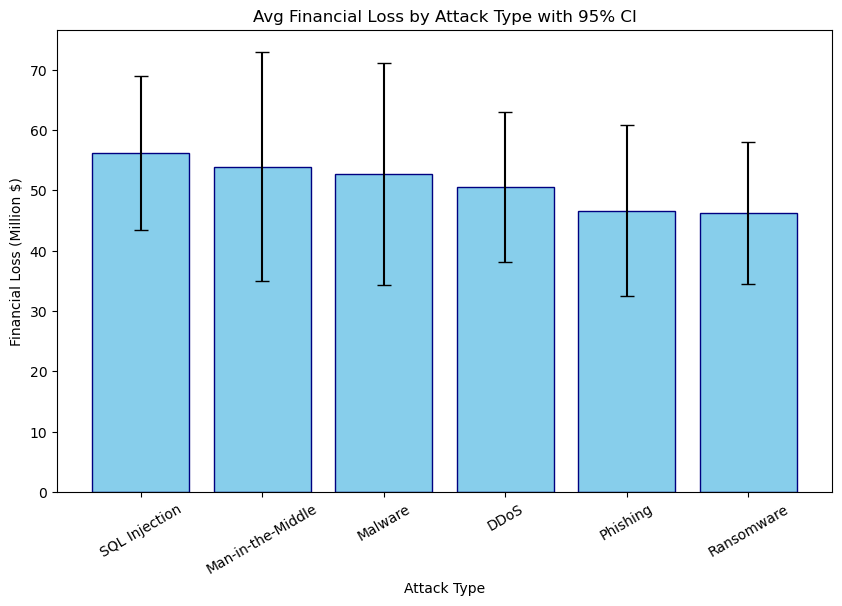

In [50]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(ci_data.index, ci_data['mean'], yerr=ci_data['ci95'], capsize=5, color='skyblue', edgecolor='navy')
ax.set_title('Avg Financial Loss by Attack Type with 95% CI')
ax.set_ylabel('Financial Loss (Million $)')
ax.set_xlabel('Attack Type')
plt.xticks(rotation=30)

In [51]:
attack_dummies = pd.get_dummies(df['Attack Type'])
correlation_df = pd.concat([df['Financial Loss (in Million $)'], attack_dummies], axis=1)
correlations = correlation_df.corr()['Financial Loss (in Million $)'].drop('Financial Loss (in Million $)')

print("Correlation between Attack Type and Financial Loss:")
print(correlations.sort_values(ascending=False))

Correlation between Attack Type and Financial Loss:
SQL Injection        0.091275
Man-in-the-Middle    0.040910
Malware              0.025716
DDoS                -0.003558
Phishing            -0.068045
Ransomware          -0.074861
Name: Financial Loss (in Million $), dtype: float64


### Question 2 Attack source and incidents.

In [11]:
overall_counts = df['Attack Source'].value_counts()
print("--- Overall Attack Source Counts ---")
print(overall_counts)

source_by_year = pd.crosstab(df['Year'], df['Attack Source'])

print("\n--- Attack Source Frequency by Year ---")
print(source_by_year)

--- Overall Attack Source Counts ---
Attack Source
Unknown         31
Hacker Group    27
Nation-state    21
Insider         21
Name: count, dtype: int64

--- Attack Source Frequency by Year ---
Attack Source  Hacker Group  Insider  Nation-state  Unknown
Year                                                       
2023                     16       10            14       13
2024                     11       11             7       18


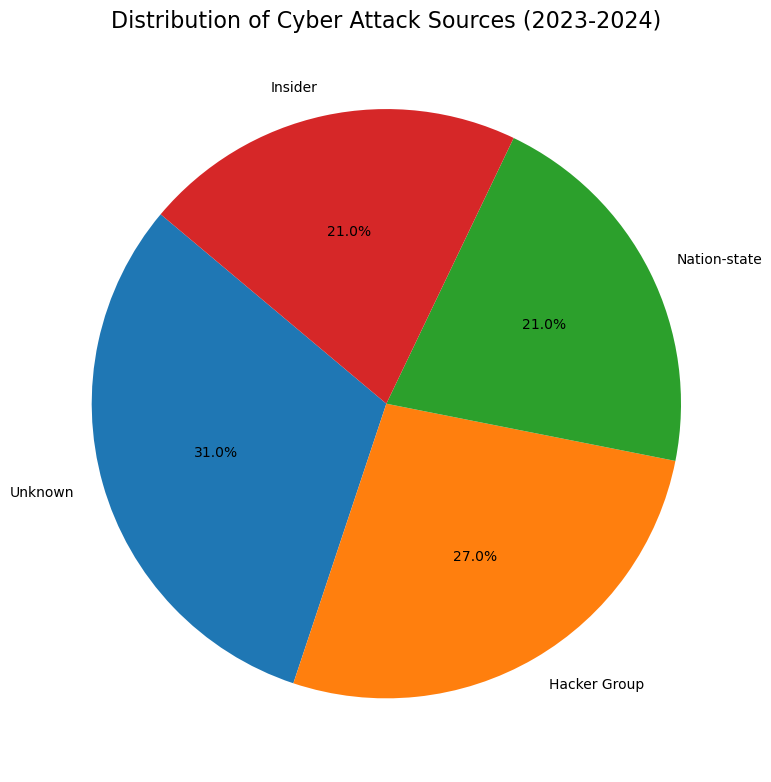

In [55]:
plt.figure(figsize=(8, 8))
plt.pie(
    overall_counts, 
    labels=overall_counts.index,
    autopct='%1.1f%%', 
    startangle=140,              
    
)

plt.title('Distribution of Cyber Attack Sources (2023-2024)', fontsize=16)

plt.tight_layout()
plt.savefig('attack_source_pie_chart.png')

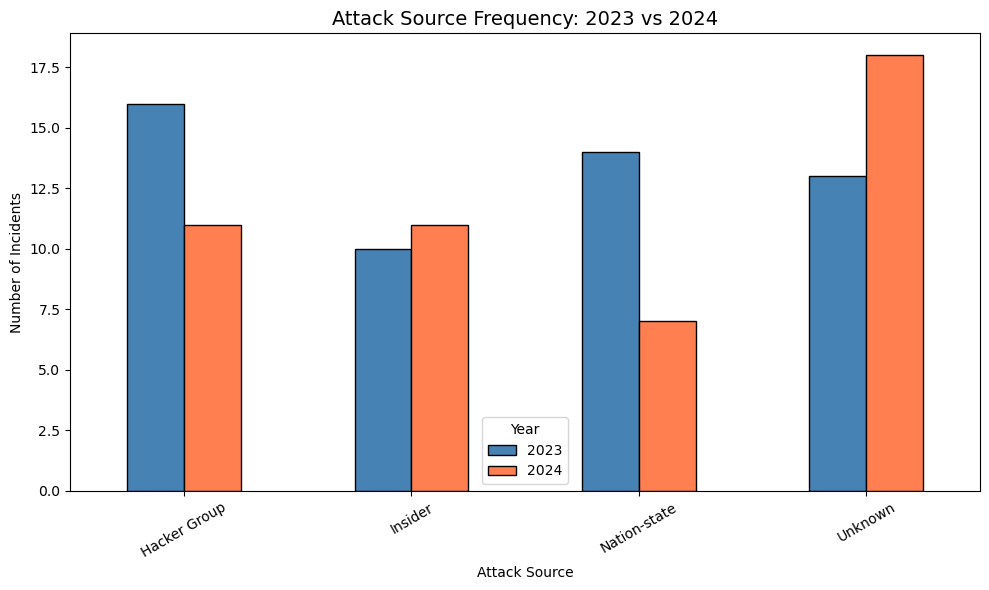

In [36]:
source_by_year = pd.crosstab(df['Attack Source'], df['Year'])

ax = source_by_year.plot(kind='bar', figsize=(10, 6), color=['steelblue', 'coral'], edgecolor='black')
plt.title('Attack Source Frequency: 2023 vs 2024', fontsize=14)
plt.xlabel('Attack Source')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=30)
plt.legend(title='Year')
plt.tight_layout()

### Question 3 Effective defence mechanisms. 

In [13]:
avg_res_time = df.groupby('Defense Mechanism Used')['Incident Resolution Time (in Hours)'].mean().sort_values(ascending=False)

print("Average Incident Resolution Time by Defense Mechanism (in Hours):")
print(avg_res_time)

defense_dummies = pd.get_dummies(df['Defense Mechanism Used'])
corr_df = pd.concat([df['Incident Resolution Time (in Hours)'], defense_dummies], axis=1)
correlation_results = corr_df.corr()['Incident Resolution Time (in Hours)'].drop('Incident Resolution Time (in Hours)')

print("\nCorrelation Coefficient with Resolution Time:")
print(correlation_results.sort_values(ascending=False))

Average Incident Resolution Time by Defense Mechanism (in Hours):
Defense Mechanism Used
Firewall              41.954545
VPN                   40.058824
Encryption            39.500000
Antivirus             38.052632
AI-based Detection    35.428571
Name: Incident Resolution Time (in Hours), dtype: float64

Correlation Coefficient with Resolution Time:
Firewall              0.086789
VPN                   0.030612
Encryption            0.015900
Antivirus            -0.016330
AI-based Detection   -0.103702
Name: Incident Resolution Time (in Hours), dtype: float64


In [14]:
from scipy import stats
groups = [df[df['Attack Type'] == at]['Financial Loss (in Million $)'] for at in df['Attack Type'].unique()]
f_stat, p_val = stats.f_oneway(*groups)

print(f"Attack Type ANOVA: F-statistic = {f_stat:.4f}, p-value = {p_val:.4f}")


groups_def = [df[df['Defense Mechanism Used'] == dm]['Incident Resolution Time (in Hours)'] for dm in df['Defense Mechanism Used'].unique()]
f_stat_def, p_val_def = stats.f_oneway(*groups_def)

print(f"Defense Mechanism ANOVA: F-statistic = {f_stat_def:.4f}, p-value = {p_val_def:.4f}")

Attack Type ANOVA: F-statistic = 0.3271, p-value = 0.8955
Defense Mechanism ANOVA: F-statistic = 0.3575, p-value = 0.8382


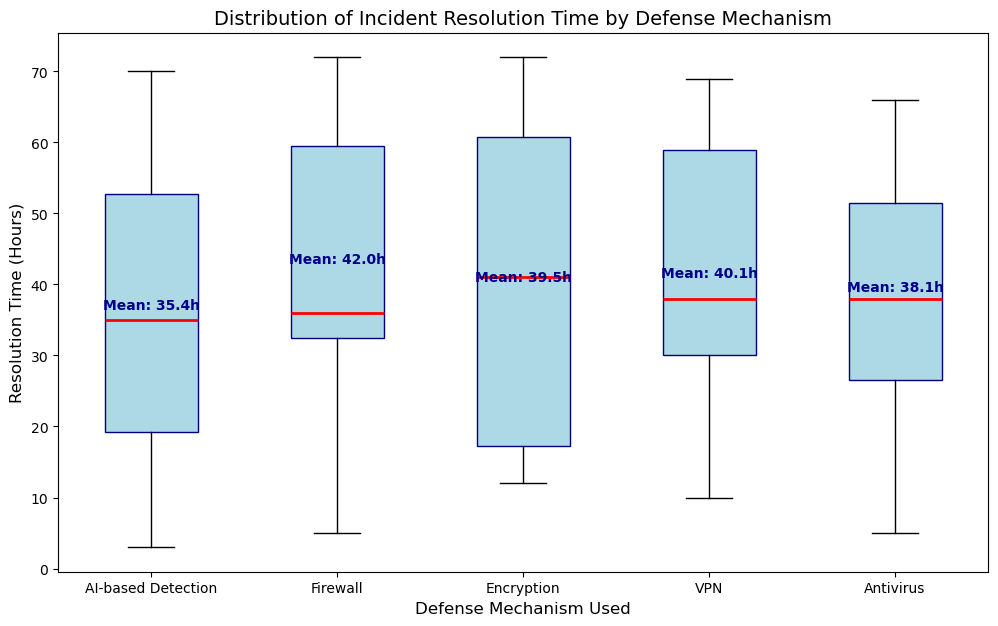

In [57]:
defense_types = df['Defense Mechanism Used'].unique()
data_to_plot = [df[df['Defense Mechanism Used'] == dm]['Incident Resolution Time (in Hours)'] for dm in defense_types]

fig, ax = plt.subplots(figsize=(12, 7))

ax.boxplot(data_to_plot, tick_labels=defense_types, patch_artist=True, 
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='red', linewidth=2))

ax.set_title('Distribution of Incident Resolution Time by Defense Mechanism', fontsize=14)
ax.set_ylabel('Resolution Time (Hours)', fontsize=12)
ax.set_xlabel('Defense Mechanism Used', fontsize=12)

for i, group in enumerate(data_to_plot):
    mean_val = group.mean()
    ax.text(i + 1, mean_val + 1, f'Mean: {mean_val:.1f}h', ha='center', color='darkblue', fontweight='bold')

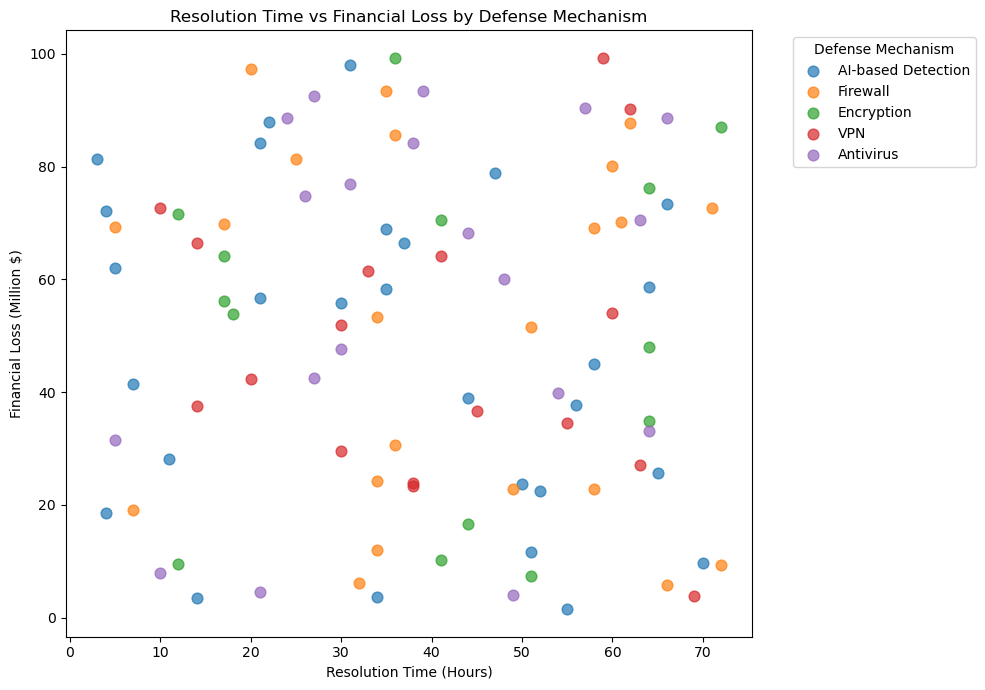

In [37]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 7))
for defense in df['Defense Mechanism Used'].unique():
    subset = df[df['Defense Mechanism Used'] == defense]
    ax.scatter(subset['Incident Resolution Time (in Hours)'],
               subset['Financial Loss (in Million $)'],
               label=defense, alpha=0.7, s=60)

ax.set_xlabel('Resolution Time (Hours)')
ax.set_ylabel('Financial Loss (Million $)')
ax.set_title('Resolution Time vs Financial Loss by Defense Mechanism')
ax.legend(title='Defense Mechanism', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

### Question 4 Industry Distribution 

In [16]:
distribution = df.groupby(['Target Industry', 'Attack Type']).size()

print("--- Incident Distribution by Industry and Attack Type ---")
print(distribution)

--- Incident Distribution by Industry and Attack Type ---
Target Industry     Attack Type      
Banking             DDoS                 3
                    Malware              3
                    Phishing             3
                    Ransomware           3
                    SQL Injection        3
Education           Malware              1
                    Phishing             4
                    Ransomware           1
                    SQL Injection        1
Government          DDoS                 2
                    Malware              2
                    Phishing             5
                    Ransomware           4
                    SQL Injection        3
Healthcare          DDoS                 5
                    Malware              3
                    Man-in-the-Middle    1
                    Phishing             1
                    Ransomware           1
                    SQL Injection        4
IT                  DDoS                 5
 

Distribution Table:
Attack Type         DDoS  Malware  Man-in-the-Middle  Phishing  Ransomware  \
Target Industry                                                              
Banking                3        3                  0         3           3   
Education              0        1                  0         4           1   
Government             2        2                  0         5           4   
Healthcare             5        3                  1         1           1   
IT                     5        1                  2         2           4   
Retail                 1        1                  4         2           2   
Telecommunications     3        1                  5         2           4   

Attack Type         SQL Injection  
Target Industry                    
Banking                         3  
Education                       1  
Government                      3  
Healthcare                      4  
IT                              1  
Retail                   

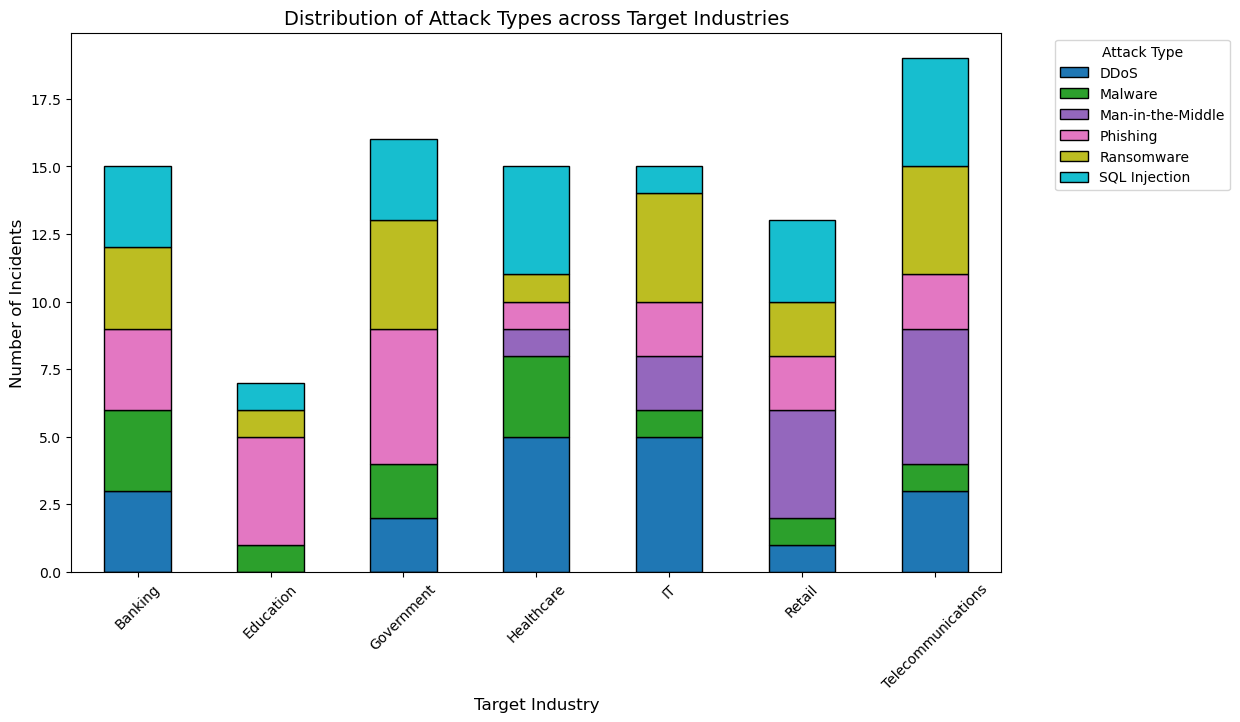

In [17]:
attack_industry_dist = pd.crosstab(df['Target Industry'], df['Attack Type'])

print("Distribution Table:")
print(attack_industry_dist)

ax = attack_industry_dist.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='tab10', edgecolor='black')

plt.title('Distribution of Attack Types across Target Industries', fontsize=14)
plt.xlabel('Target Industry', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Attack Type', bbox_to_anchor=(1.05, 1), loc='upper left')


### Conclusions

In [58]:
#Important Note: Only one coralation is significant. 

def run_anova(df, category_col, numerical_col):

    groups = [df[df[category_col] == cat][numerical_col] for cat in df[category_col].unique()]
   
    f_stat, p_val = stats.f_oneway(*groups)
    return f_stat, p_val

q1_f, q1_p = run_anova(df, 'Attack Type', 'Financial Loss (in Million $)')
q2_f, q2_p = run_anova(df, 'Attack Source', 'Financial Loss (in Million $)')
q3_f, q3_p = run_anova(df, 'Defense Mechanism Used', 'Incident Resolution Time (in Hours)')
q4_f, q4_p = run_anova(df, 'Target Industry', 'Financial Loss (in Million $)')

print(f"Q1 ANOVA (Type vs Loss): p = {q1_p:.4f}")
print(f"Q2 ANOVA (Source vs Loss): p = {q2_p:.4f} (SIGNIFICANT)")
print(f"Q3 ANOVA (Defense vs Time): p = {q3_p:.4f}")
print(f"Q4 ANOVA (Industry vs Loss): p = {q4_p:.4f}")

Q1 ANOVA (Type vs Loss): p = 0.8955
Q2 ANOVA (Source vs Loss): p = 0.0158 (SIGNIFICANT)
Q3 ANOVA (Defense vs Time): p = 0.8382
Q4 ANOVA (Industry vs Loss): p = 0.2786


#### Question 1 
##### My analysis revealed that SQL injections were the most costly attack type from 2023 to 2024. This attack type had the highest average cost, over fifty-six million. Man-in-the-middle attacks are also devastating for companies, as they can lead to an average loss of over $53 million. Even though ransomware and malware are often discussed, SQL injection and man-in-the-middle attacks are the most financially deadly. 

#### Question 2 
##### There was a shift in attack sources from 2023 to 2024. The primary source in 2023 was attack groups, but as the new year began, that shifted to an increasing number of unknown sources as hackers developed harder-to-trace methods. According to the MSSP alert, there was indeed a shift away from ransomware groups to harder-to-track untraceable sources. 

#### Question 3
##### The data shows that AI-based detection as a defence mechanism is the most efficient way to resolve attacks. AI-based detection had an average resolution time of 35.4 hours, which was over 6 hours faster than that of firewall-dependent organizations. Although I could observe a trend, the ANOVA test showed a p-value of .84, suggesting the sample size may have been too small.

#### Question 4
##### Different sectors face different threat types: Government and Education are usually targeted by phishing, Healthcare and IT are mainly targeted by DDoS, Telecommunications are typically attacked by man-in-the-middle, and Banking showed a very even distribution across attack methods. 

#### Final Takeaways 
##### With a shift towards untraceable attack methods, protecting online information is growing increasingly more difficult. However, AI detection methods are becoming the go-to defense against cybersecurity threats. With the extensive financial cost of SQL injection attacks, companies must invest in protecting their data.This process and data proved to be an okay sample; however, two of my ANOVAs returned P values greater than .5 suggesting that more data would be necessary for confident results.  

#### Future Questions
##### Why does SQL Injection cost so much to defend against? 
##### Where are these hacker groups located? 
##### How can we use AI to make even more efficient detection methods?
##### Why was telecommunications the most targeted industry in this sample? 


### Citations 

#### Data Source:
#### Soundankar, A. (2024). Global Cybersecurity Threats (2015-2024) [Data set]. Kaggle. https://www.kaggle.com/datasets/atharvasoundankar/global-cybersecurity-threats-2015-2024
#### MSSP Alert. (2024, May 22). Cyber threat trends in 2024: The landscape according to top industry reports. https://www.msspalert.com/native/cyber-threat-trends-in-2024-the-landscape-according-to-top-industry-reports